In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import pandas as pd
df = pd.read_csv("kc_house_data.csv")
print("Dataset loaded Successfully")

Dataset loaded Successfully


In [3]:
print(df.head())

           id             date     price  bedrooms  bathrooms  sqft_living  \
0  7129300520  20141013T000000  221900.0         3       1.00         1180   
1  6414100192  20141209T000000  538000.0         3       2.25         2570   
2  5631500400  20150225T000000  180000.0         2       1.00          770   
3  2487200875  20141209T000000  604000.0         4       3.00         1960   
4  1954400510  20150218T000000  510000.0         3       2.00         1680   

   sqft_lot  floors  waterfront  view  ...  grade  sqft_above  sqft_basement  \
0      5650     1.0           0     0  ...      7        1180              0   
1      7242     2.0           0     0  ...      7        2170            400   
2     10000     1.0           0     0  ...      6         770              0   
3      5000     1.0           0     0  ...      7        1050            910   
4      8080     1.0           0     0  ...      8        1680              0   

   yr_built  yr_renovated  zipcode      lat     lo

In [4]:
print(df.shape)

(21613, 21)


In [5]:
print(df.isnull().sum())

id               0
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64


In [6]:
df = df.drop_duplicates()

print("Shape after removing duplicates:")
print(df.shape)

Shape after removing duplicates:
(21613, 21)


#  Preprocessing date attributes

In [7]:
df['date'] = pd.to_datetime(df['date'])

df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['day'] = df['date'].dt.day

print(df[['date', 'year', 'month', 'day']].head())

        date  year  month  day
0 2014-10-13  2014     10   13
1 2014-12-09  2014     12    9
2 2015-02-25  2015      2   25
3 2014-12-09  2014     12    9
4 2015-02-18  2015      2   18


# Preprocessing location attributes

In [8]:
df['zipcode'] = df['zipcode'].astype(str)

df['location'] = df['lat'].astype(str) + "," + df['long'].astype(str)

print(df[['zipcode', 'lat', 'long', 'location']].head())

  zipcode      lat     long          location
0   98178  47.5112 -122.257  47.5112,-122.257
1   98125  47.7210 -122.319   47.721,-122.319
2   98028  47.7379 -122.233  47.7379,-122.233
3   98136  47.5208 -122.393  47.5208,-122.393
4   98074  47.6168 -122.045  47.6168,-122.045


# Living area feature engineering

In [10]:
df['total_area'] = df['sqft_living'] + df['sqft_lot']

df['living_area_per_bedroom'] = df['sqft_living'] / df['bedrooms'].replace(0, np.nan)

df['house_age'] = 2015 - df['yr_built']

print(df[['sqft_living', 'total_area',
          'living_area_per_bedroom', 'house_age']].head())

   sqft_living  total_area  living_area_per_bedroom  house_age
0         1180        6830               393.333333         60
1         2570        9812               856.666667         64
2          770       10770               385.000000         82
3         1960        6960               490.000000         50
4         1680        9760               560.000000         28


# House price distribution

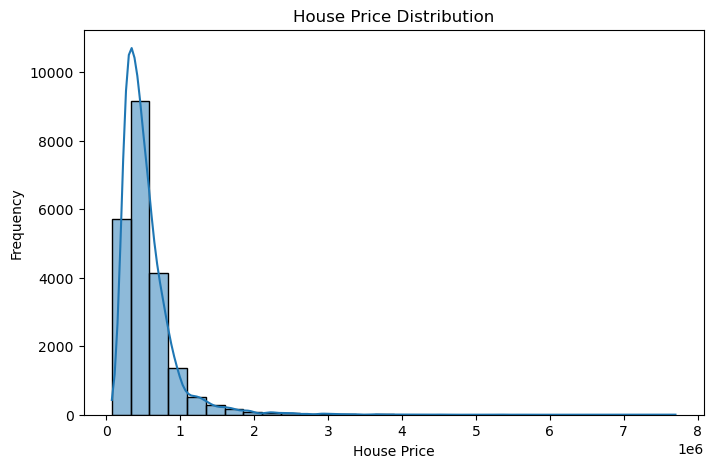

In [11]:
plt.figure(figsize=(8,5))

sns.histplot(df['price'], bins=30, kde=True)

plt.title("House Price Distribution")
plt.xlabel("House Price")
plt.ylabel("Frequency")

plt.show()

# House Sales – Real Estate Valuation & Spatial Analytics

# Waterfront premium analysis

waterfront
0    5.315636e+05
1    1.661876e+06
Name: price, dtype: float64


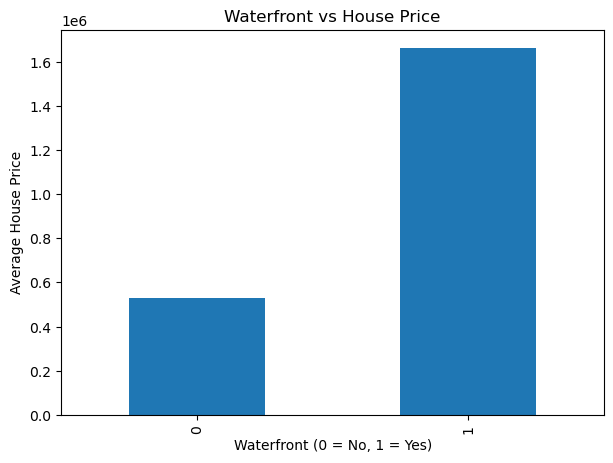

In [13]:
waterfront_price = df.groupby('waterfront')['price'].mean()

print(waterfront_price)

waterfront_price.plot(kind='bar', figsize=(7,5))

plt.title("Waterfront vs House Price")
plt.xlabel("Waterfront (0 = No, 1 = Yes)")
plt.ylabel("Average House Price")

plt.show()

# Grade vs Price impact

grade
1     1.420000e+05
3     2.056667e+05
4     2.143810e+05
5     2.485240e+05
6     3.019196e+05
7     4.025903e+05
8     5.428528e+05
9     7.735132e+05
10    1.071771e+06
11    1.496842e+06
12    2.191222e+06
13    3.709615e+06
Name: price, dtype: float64


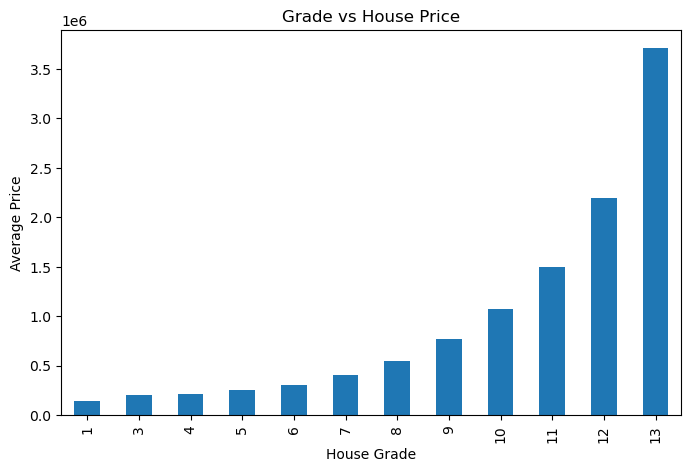

In [14]:
grade_price = df.groupby('grade')['price'].mean()

print(grade_price)

grade_price.plot(kind='bar', figsize=(8,5))

plt.title("Grade vs House Price")
plt.xlabel("House Grade")
plt.ylabel("Average Price")

plt.show()

# Geographic heatmap

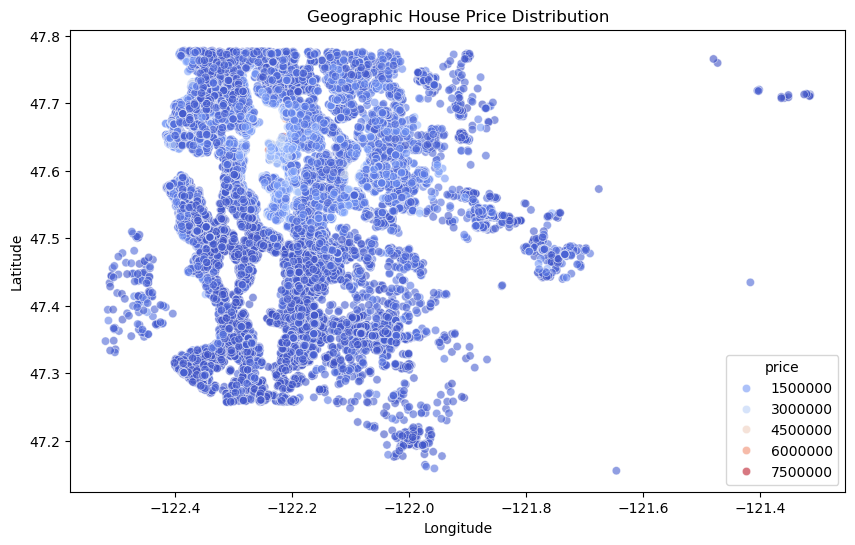

In [15]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    x='long',
    y='lat',
    hue='price',
    data=df,
    palette='coolwarm',
    alpha=0.6
)

plt.title("Geographic House Price Distribution")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.show()

# Regression trends

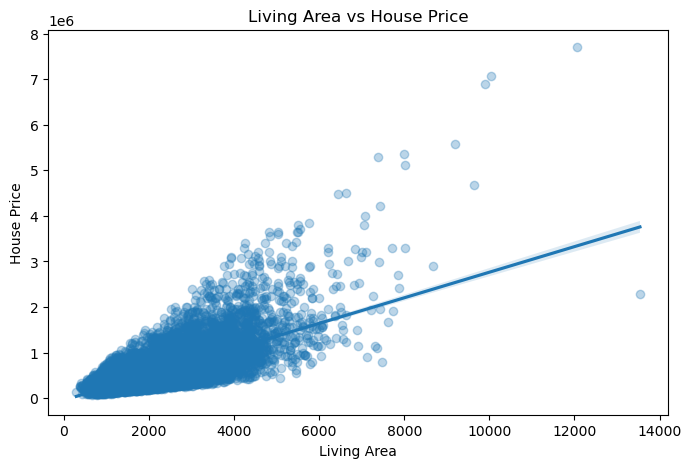

In [16]:
plt.figure(figsize=(8,5))

sns.regplot(
    x='sqft_living',
    y='price',
    data=df,
    scatter_kws={'alpha':0.3}
)

plt.title("Living Area vs House Price")
plt.xlabel("Living Area")
plt.ylabel("House Price")

plt.show()

# Grade and price regression

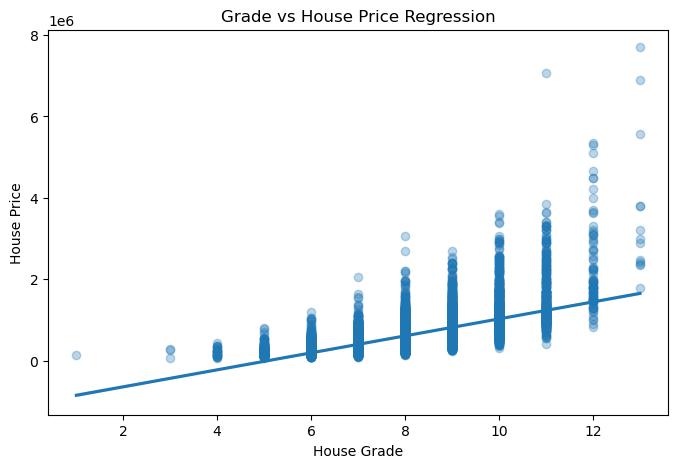

In [17]:
plt.figure(figsize=(8,5))

sns.regplot(
    x='grade',
    y='price',
    data=df,
    scatter_kws={'alpha':0.3}
)

plt.title("Grade vs House Price Regression")
plt.xlabel("House Grade")
plt.ylabel("House Price")

plt.show()